# 카카오톡 숏폼 화면 분류 모델 (담당 B)

카카오톡 화면을 4개 클래스로 분류하는 MobileNetV3-Small 모델의 데이터 구성, 전처리, 학습·비교 결과, 앱에 탑재한 ONNX 모델의 테스트 평가를 정리한 노트북입니다.

- 학습·비교 코드: `Application/ml/kakaotalk/` (`train.py`, `compare.py`, `export.py`)
- 앱 탑재 모델: `app/src/main/assets/models/kakaotalk_shortform_state.onnx`
- 원본 캡처에는 친구 이름·대화가 포함되어 저장소에 올리지 않았습니다. 이 노트북은 로컬 데이터(`ml/kakaotalk/data`)로 실행한 결과입니다.

In [1]:
import csv, hashlib, json, sys, time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import torch
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score

APP = Path('../../..').resolve()          # Application/
ML = APP / 'ml' / 'kakaotalk'
ARTIFACTS = ML / 'artifacts'
DATA = ML / 'data'
MODELS = APP / 'app' / 'src' / 'main' / 'assets' / 'models'
sys.path.insert(0, str(ML))
from common import LABELS, IMAGENET_MEAN, IMAGENET_STD, list_dataset, ui_tiles_v1

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
NAMES = {'SHORTFORM_NORMAL': '숏폼 일반', 'SHORTFORM_AD': '숏폼 광고',
         'NOW_OPENCHAT': '지금탭 기타', 'CHAT_FRIENDS': '친구·채팅'}
report = json.loads((ARTIFACTS / 'report.json').read_text(encoding='utf-8'))
print('클래스:', LABELS)

클래스: ['SHORTFORM_NORMAL', 'SHORTFORM_AD', 'NOW_OPENCHAT', 'CHAT_FRIENDS']


## 1. 데이터 구성

직접 캡처한 카카오톡 화면을 클래스별 폴더로 검수했습니다. 같은 파일이 두 번 들어간 경우는 해시로 중복을 제거했고, 펑(1장)과 광고 여부가 애매한 화면(5장)은 제외해 300장을 사용했습니다.

연속 캡처가 학습·평가에 함께 들어가지 않도록 그룹 단위로 학습 70% / 검증 15% / 테스트 15%로 나눴습니다.

총 300장
  숏폼 일반     178장
  숏폼 광고      24장
  지금탭 기타     42장
  친구·채팅      56장

분할         숏폼 일반     숏폼 광고    지금탭 기타     친구·채팅      합계
train          124          16          28          38       206
val             27           4           7           9        47
test            27           4           7           9        47


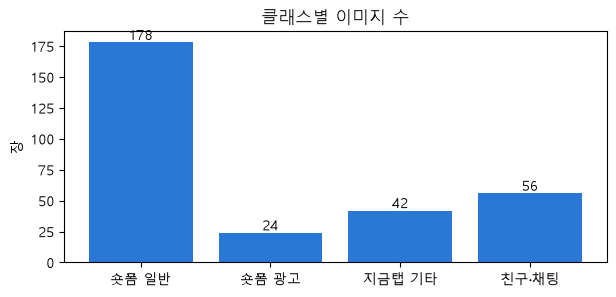

In [2]:
items = list_dataset(DATA)
counts = Counter(LABELS[label] for _, label, _ in items)
print(f'총 {len(items)}장')
for label in LABELS:
    print(f'  {NAMES[label]:<8} {counts[label]:>4}장')

print()
print(f"{'분할':<6}" + ''.join(f'{NAMES[l]:>10}' for l in LABELS) + f"{'합계':>8}")
for split, row in report['split_counts'].items():
    print(f'{split:<6}' + ''.join(f'{row[l]:>12}' for l in LABELS) + f'{sum(row.values()):>10}')

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([NAMES[l] for l in LABELS], [counts[l] for l in LABELS], color='#2a78d6')
for i, l in enumerate(LABELS):
    ax.text(i, counts[l] + 2, counts[l], ha='center')
ax.set_title('클래스별 이미지 수'); ax.set_ylabel('장')
plt.show()

## 2. 전처리: WholeUiTiles (ui_tiles_v1)

인스타그램·유튜브와 같은 전처리입니다. 320×320 검은 캔버스의 왼쪽에 전체 화면, 오른쪽 위에 화면 높이 60~85%, 오른쪽 아래에 82~97% 영역을 비율을 유지해 붙입니다. 하단의 작성자·광고 표시 같은 작은 UI 단서를 크게 보존하기 위한 구성입니다.

Python `ui_tiles_v1`과 앱의 `WholeUiTiles.kt`가 서로 다른 3개 종횡비에서 픽셀 단위로 같은지 단위 테스트(`KakaotalkPreprocessingParityTest`)로 확인했습니다. 아래 예시는 `Picture/` 폴더의 대표 사진입니다. 개인정보 보호를 위해 상단 상태바(시간·배터리)를 잘라내고 일부 영역을 모자이크한 사진이라, 실제 앱 입력(상태바 포함 전체 화면)과는 위쪽 일부가 다릅니다.

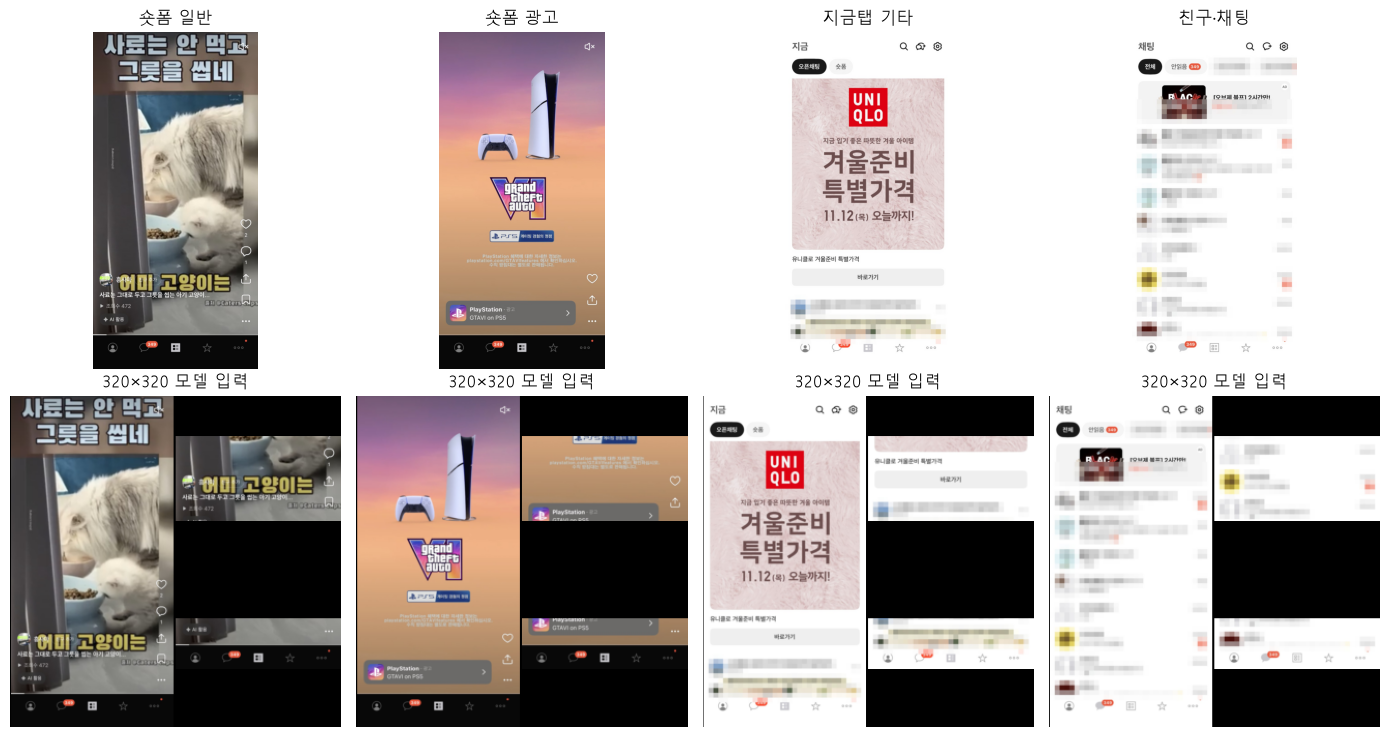

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for col, label in enumerate(LABELS):
    image = Image.open(f'Picture/{label}.jpg')
    axes[0, col].imshow(image); axes[0, col].set_title(NAMES[label])
    axes[1, col].imshow(ui_tiles_v1(image)); axes[1, col].set_title('320×320 모델 입력')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 3. 학습 설정과 하이퍼파라미터 비교

ImageNet 사전학습 MobileNetV3-Small의 마지막 분류층을 4개 출력으로 바꿔 미세조정했습니다. AdamW, CosineAnnealingLR, 최대 25 epoch, 검증 Macro F1이 6 epoch 동안 오르지 않으면 조기 종료합니다. UI 타일 위치가 바뀌지 않도록 기하 변형은 쓰지 않고 색상 변형(ColorJitter)과 RandomErasing만 적용했습니다.

학습률, 라벨 스무딩, 백본 고정 여부를 바꾼 4개 설정을 같은 분할로 학습해 검증 Macro F1로 비교했습니다.

설정                          lr  smoothing  freeze  best ep   val acc   val F1
lr1e-3_ls0.0             0.001        0.0       0        4   100.00%  100.00%
lr1e-3_ls0.1             0.001        0.1       0        6    93.62%   91.71%
lr3e-4_ls0.1            0.0003        0.1       0       25    93.62%   91.86%
lr1e-3_ls0.1_freeze3     0.001        0.1       3       18    93.62%   91.86%

선택한 설정: lr1e-3_ls0.0


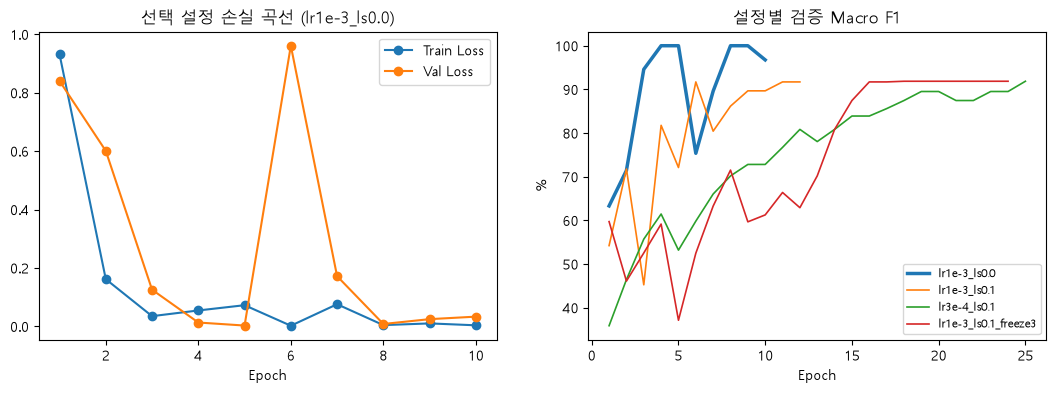

In [4]:
with open(ARTIFACTS / 'hparam_results.csv', encoding='utf-8') as f:
    hparams = list(csv.DictReader(f))
print(f"{'설정':<22}{'lr':>8}{'smoothing':>11}{'freeze':>8}{'best ep':>9}{'val acc':>10}{'val F1':>9}")
for r in hparams:
    print(f"{r['name']:<22}{r['lr']:>8}{r['label_smoothing']:>11}{r['freeze_epochs']:>8}{r['best_epoch']:>9}"
          f"{float(r['val_accuracy'])*100:>9.2f}%{float(r['val_macro_f1'])*100:>8.2f}%")
print('\n선택한 설정:', report['best_config']['name'])

with open(ARTIFACTS / 'history.csv', encoding='utf-8') as f:
    history = list(csv.DictReader(f))
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
for name in [r['name'] for r in hparams]:
    rows = [r for r in history if r['config'] == name]
    epochs = [int(r['epoch']) for r in rows]
    width = 2.5 if name == report['best_config']['name'] else 1.2
    right.plot(epochs, [float(r['val_macro_f1']) * 100 for r in rows], label=name, linewidth=width)
best = [r for r in history if r['config'] == report['best_config']['name']]
ep = [int(r['epoch']) for r in best]
left.plot(ep, [float(r['train_loss']) for r in best], 'o-', label='Train Loss')
left.plot(ep, [float(r['val_loss']) for r in best], 'o-', label='Val Loss')
left.set_title(f"선택 설정 손실 곡선 ({report['best_config']['name']})"); left.set_xlabel('Epoch'); left.legend()
right.set_title('설정별 검증 Macro F1'); right.set_xlabel('Epoch'); right.set_ylabel('%'); right.legend(fontsize=8)
plt.show()

검증셋이 47장으로 작아 검증 100%는 과대평가입니다. 최종 성능은 선택에 쓰지 않은 테스트셋으로 아래에서 평가합니다.

## 4. 모델·전처리 후보 비교

같은 분할·하이퍼파라미터로 모델 3종과 전처리 2종을 비교했습니다. 추론 시간은 PC CPU 기준 상대 비교값입니다.

후보                              test acc  test F1    크기(MB)  PC CPU(ms)
MobileNetV3-Small + UI 타일         93.62%   90.67%       6.1        41.3
MobileNetV3-Small + 전체화면 축소       95.74%   92.82%       6.1        41.1
MobileNetV3-Large + UI 타일         95.74%   90.77%      16.8        60.8
ResNet-18 + UI 타일                 97.87%   96.75%      44.7        83.8


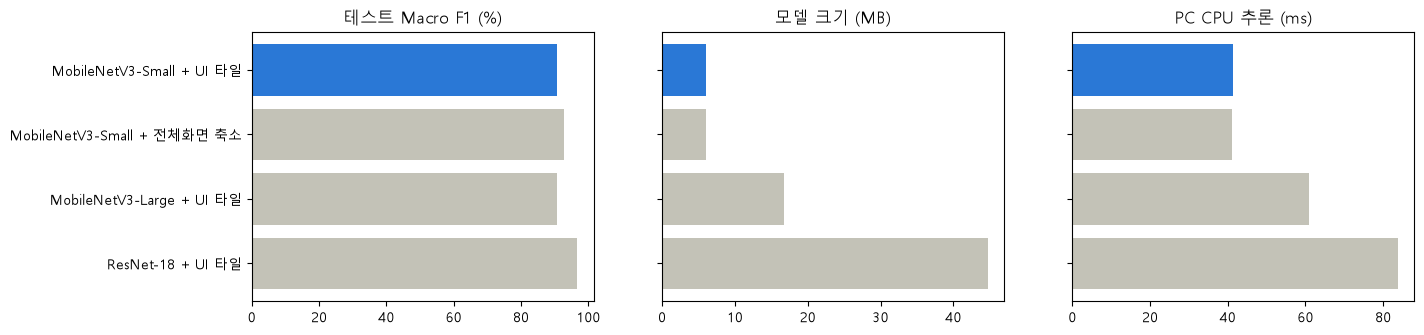

In [5]:
with open(ARTIFACTS / 'compare_results.csv', encoding='utf-8') as f:
    compare = list(csv.DictReader(f))
print(f"{'후보':<30}{'test acc':>10}{'test F1':>9}{'크기(MB)':>10}{'PC CPU(ms)':>12}")
for r in compare:
    print(f"{r['candidate']:<30}{float(r['test_accuracy'])*100:>9.2f}%{float(r['test_macro_f1'])*100:>8.2f}%"
          f"{r['size_mb']:>10}{r['pc_cpu_latency_ms']:>12}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
names = [r['candidate'] for r in compare]
colors = ['#2a78d6'] + ['#c3c2b7'] * (len(compare) - 1)
for ax, (key, title, scale) in zip(axes, [('test_macro_f1', '테스트 Macro F1 (%)', 100),
                                          ('size_mb', '모델 크기 (MB)', 1), ('pc_cpu_latency_ms', 'PC CPU 추론 (ms)', 1)]):
    ax.barh(names, [float(r[key]) * scale for r in compare], color=colors)
    ax.set_title(title)
axes[0].invert_yaxis()
plt.show()

ResNet-18이 가장 정확하지만 크기가 7배, 추론 시간이 2배입니다. 접근성 이벤트마다 폰에서 실시간으로 판정해야 하므로 가장 작고 빠른 MobileNetV3-Small을 앱에 적용했습니다. 전처리는 이번 테스트셋에서 전체화면 축소가 1장 더 맞혔지만 1장이 약 2.1%포인트라 의미 있는 차이로 보기 어렵고, 인스타그램·유튜브와 같은 `WholeUiTiles` 코드를 재사용하기 위해 UI 타일을 유지했습니다.

## 5. 앱 탑재 ONNX 모델 테스트 평가

앱 assets에 들어 있는 ONNX 파일을 그대로 불러와 SHA-256을 metadata와 대조한 뒤, 학습에 쓰지 않은 테스트셋 47장을 평가합니다.

In [6]:
onnx_path = MODELS / 'kakaotalk_shortform_state.onnx'
metadata = json.loads((MODELS / 'kakaotalk_shortform_state.json').read_text(encoding='utf-8'))
digest = hashlib.sha256(onnx_path.read_bytes()).hexdigest()
print('SHA-256 일치:', digest == metadata['sha256'])
print('라벨:', metadata['labels'], '/ 입력:', metadata['input_shape'], '/ 출력:', metadata['output_shape'])
print('클래스별 확정 임계값:', metadata['decision_thresholds'])

checkpoint = torch.load(ARTIFACTS / 'best.pt', map_location='cpu', weights_only=False)
test_files = [DATA / Path(p).parent.name / Path(p).name for p in checkpoint['test_files']]
session = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
mean, std = np.array(IMAGENET_MEAN, np.float32), np.array(IMAGENET_STD, np.float32)

y_true, y_pred, latencies = [], [], []
for path in test_files:
    tile = (np.asarray(ui_tiles_v1(Image.open(path)), np.float32) / 255 - mean) / std
    started = time.perf_counter()
    logits = session.run(['logits'], {'screen': tile.transpose(2, 0, 1)[None]})[0][0]
    latencies.append((time.perf_counter() - started) * 1000)
    y_true.append(LABELS.index(path.parent.name)); y_pred.append(int(logits.argmax()))
y_true, y_pred = np.array(y_true), np.array(y_pred)

correct = int((y_true == y_pred).sum())
print(f'\n테스트 정확도: {correct} / {len(y_true)} = {correct / len(y_true) * 100:.2f}%')
print(f"테스트 Macro F1: {f1_score(y_true, y_pred, average='macro') * 100:.2f}%")
print(f'PC CPU 평균 추론 시간: {np.mean(latencies):.1f}ms (1장, 전처리 제외)')
print()
print(classification_report(y_true, y_pred, labels=range(len(LABELS)), target_names=LABELS, digits=4))

SHA-256 일치: True
라벨: ['SHORTFORM_NORMAL', 'SHORTFORM_AD', 'NOW_OPENCHAT', 'CHAT_FRIENDS'] / 입력: [1, 3, 320, 320] / 출력: [1, 4]
클래스별 확정 임계값: {'SHORTFORM_NORMAL': 0.55, 'SHORTFORM_AD': 0.55, 'NOW_OPENCHAT': 0.55, 'CHAT_FRIENDS': 0.55}



테스트 정확도: 44 / 47 = 93.62%
테스트 Macro F1: 90.67%
PC CPU 평균 추론 시간: 2.2ms (1장, 전처리 제외)

                  precision    recall  f1-score   support

SHORTFORM_NORMAL     0.9615    0.9259    0.9434        27
    SHORTFORM_AD     0.7500    0.7500    0.7500         4
    NOW_OPENCHAT     0.8750    1.0000    0.9333         7
    CHAT_FRIENDS     1.0000    1.0000    1.0000         9

        accuracy                         0.9362        47
       macro avg     0.8966    0.9190    0.9067        47
    weighted avg     0.9380    0.9362    0.9363        47



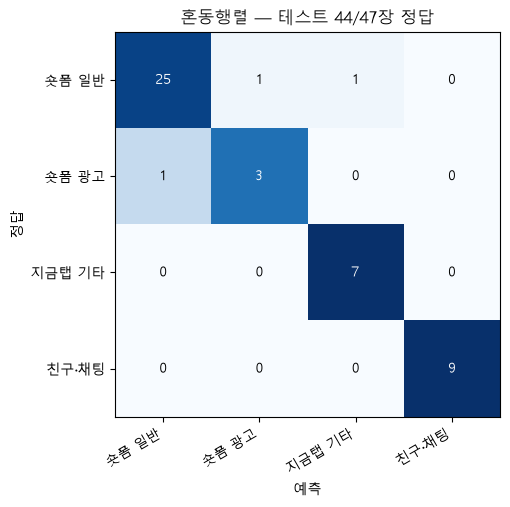

오답: 숏폼 일반 → 숏폼 광고 1장
오답: 숏폼 일반 → 지금탭 기타 1장
오답: 숏폼 광고 → 숏폼 일반 1장


In [7]:
matrix = confusion_matrix(y_true, y_pred, labels=range(len(LABELS)))
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(matrix / matrix.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
ticks = [NAMES[l] for l in LABELS]
ax.set_xticks(range(len(LABELS)), ticks, rotation=30, ha='right'); ax.set_yticks(range(len(LABELS)), ticks)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, matrix[i, j], ha='center', va='center',
                color='white' if matrix[i, j] > matrix[i].sum() * 0.55 else 'black')
ax.set_xlabel('예측'); ax.set_ylabel('정답'); ax.set_title(f'혼동행렬 — 테스트 {correct}/{len(y_true)}장 정답')
plt.show()

for i, j in zip(*np.nonzero(matrix - np.diag(np.diag(matrix)))):
    print(f'오답: {NAMES[LABELS[i]]} → {NAMES[LABELS[j]]} {matrix[i, j]}장')

## 6. 결론과 한계

- 앱에 탑재한 MobileNetV3-Small ONNX 모델의 테스트 정확도는 **44/47 = 93.62%**, Macro F1은 **90.67%**입니다.
- 앱에서는 담당 A의 추적 흐름이 영상 키를 확정하면 화면을 캡처해 한 번 판정하고, 일반 숏폼만 시청 시간·횟수에 집계합니다.
- 학습 캡처는 iPhone 화면이며, 안드로이드 실기기에서의 정확도는 추가 확인이 필요합니다.
- 테스트셋이 47장(광고 4장)으로 작아 광고 F1은 1장 차이로 크게 변합니다.
- 펑은 표본이 1장뿐이라 클래스에서 제외했습니다.